# KQC Simple — one Swissmon capacitively coupled to a through line (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' minimal connected chip, `chips/simple.py` (class `Simple`, default parameters,
chip name "Simple"; © IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`third_party/KQCircuits/klayout_package/python/kqcircuits/chips/simple.py`; spec `docs/designs/kqc/test_chips.md`,
row *Simple*: "the smoke test for KQC parity"). Three SMA8 launchers (WN, EN, SE); a Swissmon whose flux line
comes straight from WN; its coupler 1 feeds a finger capacitor C1 into a T; the T's right arm goes to EN, its
bottom arm through a second finger capacitor C2 to SE.

This notebook **rebuilds** that chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm (the SMA8 launchers sit on its edges), Quantcore die frame, device ID "Simple" |
| launchers | SMA8 (WN, EN, SE enabled), `launcher_indent` 800 µm (outer etch 20 µm from the edge) | same three, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm) |
| substrate | silicon εr 11.45 (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junction | KQC Manhattan SQUID (assumed L_J 12 nH) | Quantcore trilayer SQUID, 2 × 0.25 × 0.6 µm, R_n 45 kΩ in parallel, L_J 6.73 nH |
| cheese | KQC's whole-area ground grid (`with_grid`, 5 µm holes on a 10 µm step, in KQC's mask builds) | **the original wins:** KQC's grid (`with_grid=True`), so no PDK band |
| elements, positions, routes | — | kept exactly |
| placement | everything on the WN–EN line (y = 7200) and the SE column (x = 7200) | **kept off-centre on purpose** (content centre 879 µm below the die centre, see step 6): the three fixed launcher ports set the content box, so no shift of the inner parts can centre it |

**Kept exactly (same KQC cells, parameters and positions):** the SMA8 launchers with only WN, EN, SE enabled;
the `Swissmon` (`cpl_length=[0, 150, 0]`) rotated 270° at (2500, 7200); C1 and C2,
`FingerCapacitorSquare(finger_width=20, finger_length=100, finger_number=7)` at (5000, 7200) and, rotated 270°,
at (7200, 5000); the `WaveguideCoplanarSplitter` T (lengths 11/11/11 µm) at (7200, 7200); the six straight CPWs
WN → flux, cplr1 → C1, C1 → T, T → EN, T → C2, C2 → SE.

**Simplified:** nothing in the geometry; KQC's `Simple` has no junction-test arrays or other extras.

The notebook walks through the build step by step: setup and the PDK → die and frame → launchers → components →
routes → DRC → netlist → LOM simulation → FEM jobs → results back → one design change → fab export →
snapshots (and an XOR with KQC's own build) → summary.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips corner rounding of the grid holes in the fab step (`qcc mask` writes the full file).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")               # design JSON + final snapshots
STEPS = Path("build/snapshots/simple")  # step-by-step snapshots (build/ is not kept in the repo)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junction from the PDK rule.** KQC draws a SQUID in the Swissmon. `trilayer_junction` turns it into the
Quantcore trilayer SQUID: two junctions whose straight finger is KQC's `junction_width` (the bent finger stays at
the PDK 0.6 µm). With the nominal L_J (6.73 nH, the 0.5 × 0.6 µm junction at R_n 45 kΩ) as the SQUID's parallel
total, each junction is 0.25 × 0.6 µm. `JJ_PARAMS` go on the cell, `JUNCTION` (L_J, C_J) is what the LOM and the
FEM junction port use.

In [4]:
LJ_PDK = trilayer_junction("Swissmon")[1]["Lj_nH"]          # PDK nominal L_J (0.5 × 0.6 µm junction, R_n 45 kΩ)
JJ_PARAMS, JUNCTION = trilayer_junction("Swissmon", lj_nH=LJ_PDK, squid=True)
print("cell parameters:", JJ_PARAMS)
print("LOM junction:   ", JUNCTION)

cell parameters: {'junction_type': 'Quantcore Squid', 'junction_width': 0.25}
LOM junction:    {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


## 3 · The die and its frame

`Designer(...)` starts the chip: the 10 × 10 mm box, the SMA8 sample holder with only WN, EN and SE enabled, and
the chip name "Simple", which the Quantcore frame writes as the device ID on a free edge. `with_grid=True` asks
for KQC's whole-area ground grid (the original's cheese); the PDK band is then not added (chip `cheese` stays
`"auto"`). The frame is the PDK default (L dicing markers 1000/0, 3 × 3 alignment grids 1001/0, boundary
100/0); KQC's own `ChipFrame` is not drawn.

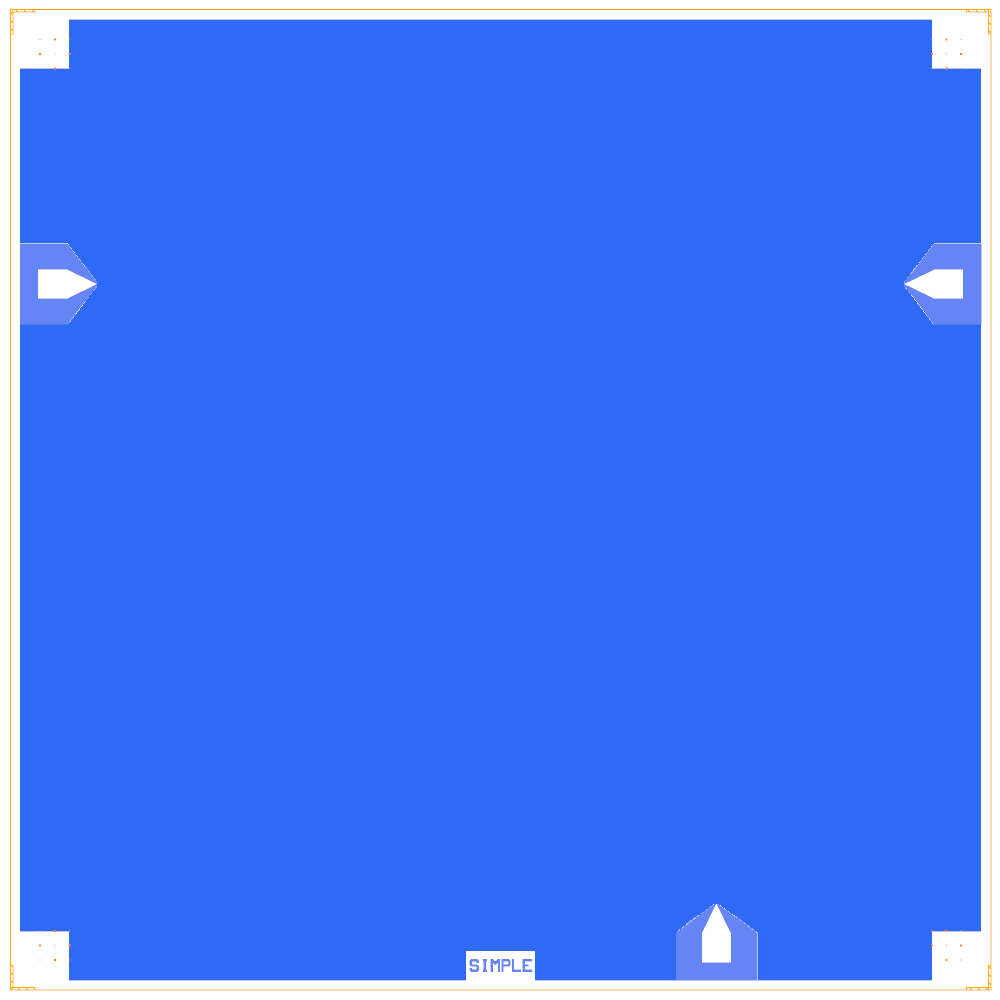

In [5]:
d = Designer("simple", box=(0, 0, 10000, 10000), launchers={"type": "SMA8", "enabled": ["WN", "EN", "SE"]},
             chip={"name_chip": "Simple", "with_grid": True}, live=LIVE)
snap(d, STEPS / "1_die.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 4 · Launchers and the pad rule

**PDK rule:** a launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge. For SMA8 (RF
launcher: 300 µm taper + 300 µm pad + 180 µm frame gap) the Designer sets `launcher_indent` = 100 + 300 + 300 +
180 = **880 µm** (KQC: 800 µm). The routes below start at the launcher ports, so the 80 µm shift needs no other
change. (Stand-alone pads take `edge="auto"` in `d.add`; this chip has none.)

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.EN | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.SE | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.WN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

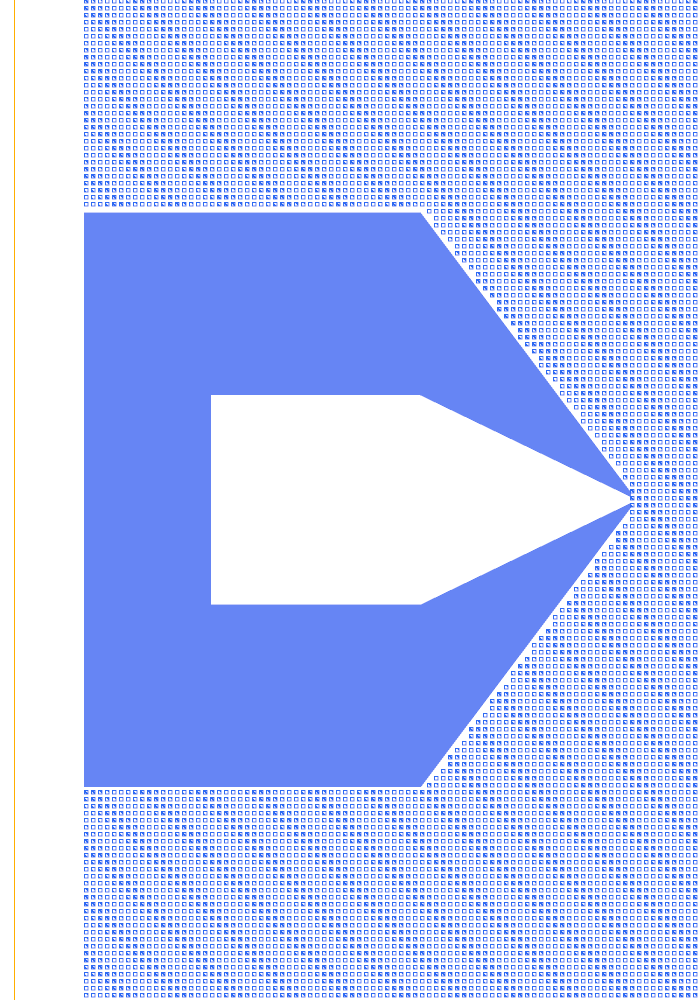

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, "chip.WN")
snap(d, STEPS / "2_launcher.png", box=(-20, y - 400, x + 100, y + 400), size=(700, 1000), width=300);

## 5 · Components

**The qubit.** A KQC `Swissmon` (cross-shaped island with three couplers and a flux line) rotated 270° at
(2500, 7200), with only coupler 1 drawn (`cpl_length=[0, 150, 0]`: 150 µm). Ports: `cplr0`–`cplr2`, `drive`,
`flux`. The SQUID at the end of one arm carries the trilayer junction parameters from step 2.

**Capacitors and the T.** C1 and C2 are the same `FingerCapacitorSquare` (7 fingers of 100 × 20 µm): C1 couples
the qubit's coupler to the line, C2 sits on the T's bottom arm towards SE. The `WaveguideCoplanarSplitter` T
(three 11 µm arms) splits the line at (7200, 7200).

<Swissmon QB ports=['cplr0', 'cplr1', 'cplr2', 'drive', 'flux']>
<FingerCapacitorSquare C1 ports=['a', 'b']>
<WaveguideCoplanarSplitter T ports=['bottom', 'left', 'right']>


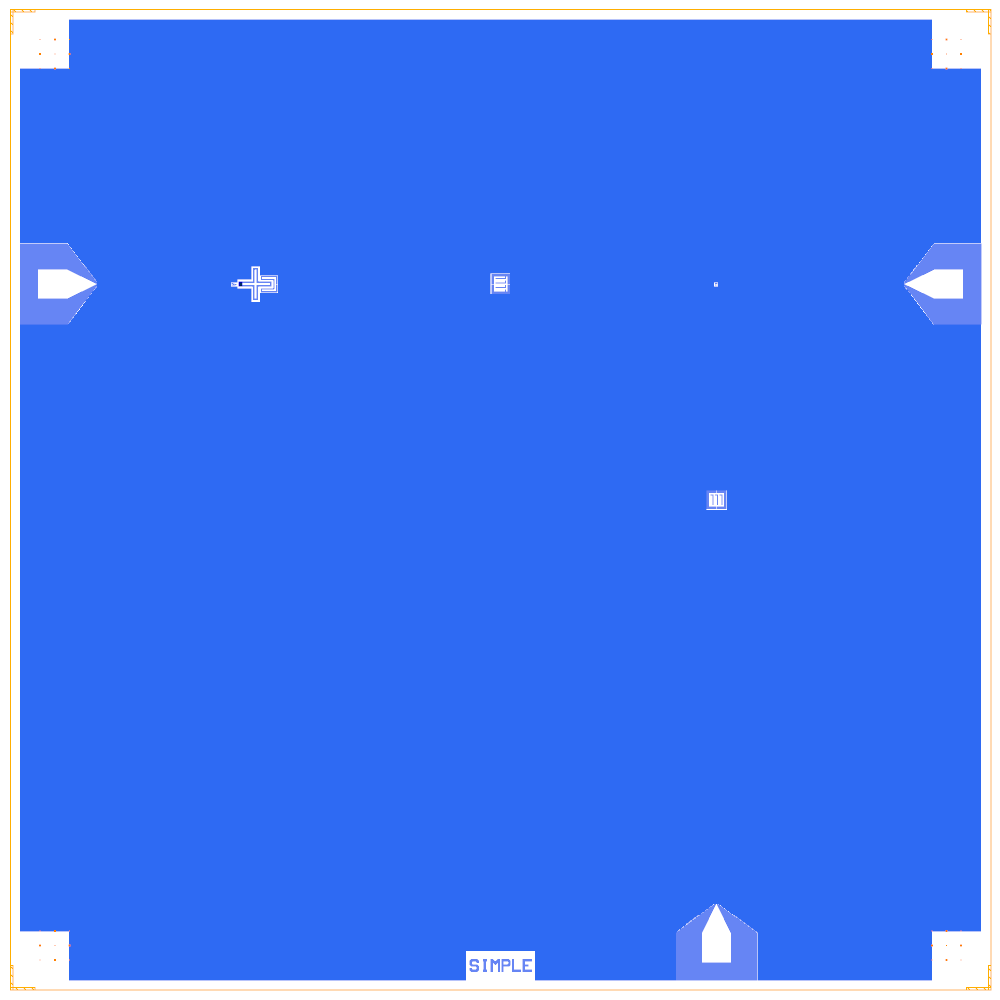

In [7]:
with d.batch():
    q = d.add("QB", "Swissmon", at=(2500, 7200), rot=270, cpl_length=[0, 150, 0], junction=JUNCTION, **JJ_PARAMS)
    cap = dict(finger_width=20, finger_length=100, finger_number=7)
    c1 = d.add("C1", "FingerCapacitorSquare", at=(5000, 7200), **cap)
    c2 = d.add("C2", "FingerCapacitorSquare", at=(7200, 5000), rot=270, **cap)
    t = d.add("T", "WaveguideCoplanarSplitter", at=(7200, 7200), lengths=[11, 11, 11],
              port_names=["right", "left", "bottom"])
print(q, c1, t, sep="\n")
snap(d, STEPS / "3_components.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 6 · Routes

Six straight CPWs (PDK default a = 10, b = 6 µm): the flux line from WN to the qubit's flux port, and the
signal path cplr1 → C1 → T → EN with the branch T → C2 → SE. All ends are ports, so the routes follow the
launchers and components wherever they are.

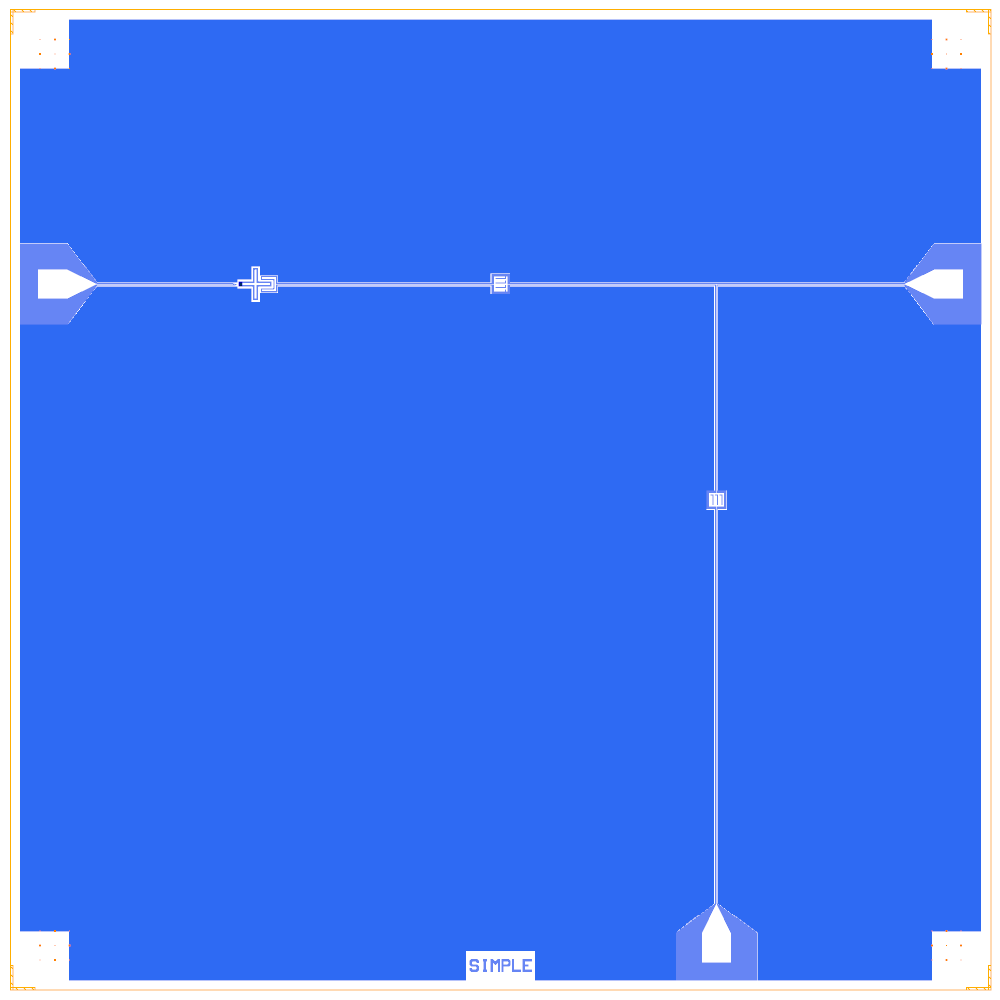

{'FLUX': 1374.67, 'W1': 2189.5, 'W2': 2097.5, 'W3': 1909.0, 'W4': 2097.5, 'W5': 4028.5}


In [8]:
with d.batch():
    d.route("FLUX", "chip.WN", q.flux)
    d.route("W1", q.cplr1, c1.a)
    d.route("W2", c1.b, t.left)
    d.route("W3", t.right, "chip.EN")
    d.route("W4", t.bottom, c2.a)
    d.route("W5", c2.b, "chip.SE")
snap(d, STEPS / "4_routes.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)
print({k: round(v, 2) for k, v in d.result.route_lengths().items()})

**Sim group, placement, save.** One sim group: the qubit with C1 (Q3D C-matrix and eigenmode).

**Placement: kept off-centre on purpose.** The PDK asks for content centred in the die, but on this chip the
launchers set the content box. The qubit, C1 and the T sit on the straight line WN → EN (y = 7200) and C2 on the
straight T → SE (x = 7200), so the box runs from the SE launcher port (y = 880 µm) to the top of the WN–EN line
(y ≈ 7362 µm); in x it spans WN to EN and is centred. Its centre is ≈ 879 µm below the die centre. The
launchers belong to the SMA8 sample holder and do not move, so shifting the inner parts cannot centre the box:
`center_in_die` would lift the line by 879 µm, bend the WN → EN line at both ends, and still leave the box
≈ 440 µm low, because its bottom stays at the SE port. A centred box would need the line ≈ 1.76 mm above the
launchers it joins. So `center_in_die` is not applied; the offset is printed and reported in `pdk_report`
below. Then `simple.json` is saved.

In [9]:
d.sim_group("QB_C1", ["QB", "C1"], analyses=["q3d_cmatrix", "eigenmode_epr"])
rebuild(d)
box = content_box(d)
print(f"content centre − die centre: ({box.center().x - 5000:+.0f}, {box.center().y - 5000:+.0f}) µm "
      "(kept: the source is anchored to the fixed SMA8 launchers)")
DESIGN = d.save(OUT / "simple.json")
print(d, "→", DESIGN)

content centre − die centre: (+0, -879) µm (kept: the source is anchored to the fixed SMA8 launchers)
<Designer simple: 4 instances, 6 routes, live=False> → examples\designs\kqc\simple.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Here:** the warnings are the Swissmon's zero-length couplers 0 and 2 (`cpl_length=[0, 150, 0]`; the LOM puts
their ports on ground) and its unused drive port (KQC's `Simple` has no charge line). No PDK design warning: the
`pdk_rn` check applies the 40–50 kΩ window to the device, i.e. the SQUID's parallel R_n (two 90 kΩ junctions =
45 kΩ, what a probe station measures across it).

In [10]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 3 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 3 | QB.cplr0 is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, -879) µm |
| junction types | Quantcore Squid × 1 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit nodes,
routes join nodes, launchers are 50 Ω ports or drive / flux controls. Swissmon → island node (C and the SQUID
to ground) and a coupler-1 node (C_g to the island, C to ground); the flux line is a flux control on the SQUID;
C1 joins the coupler node to the T node; the T and its routes are one through-line node between EN (50 Ω) and,
via C2, SE (50 Ω).

In [11]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**QB's ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith("QB."))))

**5 nodes · 12 branches · 1 controls · 2 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `QB` | `QB.island` |
| `QB.cplr1` | `QB.cplr1`, `C1.a` |
| `C1.b` | `C1.b`, `C2.a`, `T.t`, `chip.EN` |
| `C2.b` | `C2.b`, `chip.SE` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_QB` | C | `QB` – `gnd` | 78.4 fF |
| `J_QB` | SQUID | `QB` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB_cplr1` | C | `QB` – `QB.cplr1` | 4.8 fF |
| `Cc_QB_cplr1` | C | `QB.cplr1` – `gnd` | 80.7 fF |
| `C_C1` | C | `QB.cplr1` – `C1.b` | 75.5 fF |
| `C_C1_a` | C | `QB.cplr1` – `gnd` | 23 fF |
| `C_C1_b` | C | `C1.b` – `gnd` | 23 fF |
| `C_C2` | C | `C1.b` – `C2.b` | 75.5 fF |
| `C_C2_a` | C | `C1.b` – `gnd` | 23 fF |
| `C_C2_b` | C | `C2.b` – `gnd` | 23 fF |
| `Port_EN` | R | `C1.b` – `gnd` | 50 Ω |
| `Port_SE` | R | `C2.b` – `gnd` | 50 Ω |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `FLUX` | flux_bias | `J_QB` | `FLUX` | 1375 |

**Unconnected ports:** `QB.cplr0`, `QB.cplr2`

**Builder notes:**

- QB.cplr0: cpl_length 0 (no coupler), its port ends on ground
- QB.cplr2: cpl_length 0 (no coupler), its port ends on ground
- Port_WN: both ends on gnd after merging conductors (dropped)

**QB's ports → circuit nodes:**

| port | node |
|---|---|
| `QB.cplr0` | `gnd` |
| `QB.cplr1` | `QB.cplr1` |
| `QB.cplr2` | `gnd` |
| `QB.drive` | `control:drive` |
| `QB.flux` | `control:flux` |

## 9 · LOM simulation

The whole circuit has one qubit mode: QuCat gives its frequency, anharmonicity and decay rate κ into the two
50 Ω launchers through C1 (the Purcell-type T1 limit of this chip); QuTiP the dressed f_q and α. Expected with
the PDK SQUID: f_q ≈ 6.0 GHz (KQC's assumed 12 nH gave ≈ 4.7 GHz), α ≈ −214 MHz, κ ≈ 0.4 MHz (T1 ≈ 0.4 µs: a
strongly coupled smoke-test chip, not a qubit you would keep).

In [12]:
res = simulate_lom(lb, d.design, max_modes=1)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res)))
qm = res.modes[0]
display(Markdown(f"κ = {qm.kappa_MHz:.3g} MHz → T1 (into the line) = {1 / (2 * math.pi * qm.kappa_MHz * 1e6) * 1e6:.3g} µs"))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| QB | qubit | 6.1929 | 0.425 | 197.5 | J_QB 1.00 |

| parameter | LOM (QuTiP) | target |
|---|---|---|
| `QB.f_q_GHz` | 5.9885 | – |
| `QB.alpha_MHz` | -214.17 | – |

κ = 0.425 MHz → T1 (into the line) = 0.374 µs

## 10 · FEM: send the jobs

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs` solves each Ansys job in a **new
batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: the qubit with C1, a Q3D C-matrix (replaces the Swissmon estimate and C1) and an eigenmode job in which
every line leaving the box ends in 50 Ω, so the mode Q gives the qubit's decay into the line.

In [13]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

2 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| QB_C1 · q3d_cmatrix | `build/jobs/simple_QB_C1_q3d_cmatrix` | 1 · junction · `QB.junction`<br>2 · edge · `FLUX`<br>3 · edge · `W2` | `QB.island`, `W2`, `QB.cplr1` |
| QB_C1 · eigenmode_epr | `build/jobs/simple_QB_C1_eigenmode_epr` | 1 · junction · `QB.junction`<br>2 · edge_lumped · `FLUX`<br>3 · edge_lumped · `W2` | `QB.island`, `FLUX`, `W2`, `QB.cplr1` |

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls
`fill(model, design, job)`: the C-matrix (or eigenmode) values replace the component estimates branch by
branch (matched by net name), and the table compares the two. `simulate(filled)` re-runs the LOM on the
extracted values. Until then the cell says which jobs are still waiting.

In [14]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md or "No FEM jobs."))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for QB_C1 · q3d_cmatrix, QB_C1 · eigenmode_epr: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

A design change is a parameter change in the design, a rebuild and a new LOM run. Here: give C1 four fingers
instead of seven. The coupling capacitance to the line drops, so κ falls (≈ by half) and T1 into the line
doubles; f_q and α barely move. The change is made on a copy (`design_copy`), so `simple.json` keeps KQC's
seven fingers.

In [15]:
d2 = design_copy(DESIGN)
d2["C1"].set(finger_number=4)
res2 = simulate_lom(d2.lom(), d2.design, max_modes=1)
display(Markdown("**C1: 7 → 4 fingers**\n\n" + params_delta_md(res, res2)))
k1, k2 = res.modes[0].kappa_MHz, res2.modes[0].kappa_MHz
display(Markdown(f"| | before | after |\n|---|---|---|\n| κ (MHz) | {k1:.3g} | {k2:.3g} |\n"
                 f"| T1 into the line (µs) | {1e6 / (2 * math.pi * k1 * 1e6):.3g} | {1e6 / (2 * math.pi * k2 * 1e6):.3g} |"))

**C1: 7 → 4 fingers**

| parameter | before | after | Δ |
|---|---|---|---|
| `QB.f_q_GHz` | 5.9885 | 5.9896 | +0.001094 |
| `QB.alpha_MHz` | -214.17 | -214.25 | -0.07946 |

| | before | after |
|---|---|---|
| κ (MHz) | 0.425 | 0.214 |
| T1 into the line (µs) | 0.374 | 0.745 |

## 13 · Build and export

**The design file.** `simple.json` (saved in step 6) is the whole design: `qcc build
examples/designs/kqc/simple.json` rebuilds `build/simple.oas` + its sidecar from it, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0
keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm, plus every grid hole), the trilayer fingers 2/0 + 4/0 and spacer 50/0
with the 51–53/0 dose gradient, and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: KQC's grid
drawn in the build (`with_grid=True`) stands and no PDK band is added. Corner rounding (fab only) is skipped
unless `FULL_FAB`; `qcc mask examples/designs/kqc/simple.json` writes the complete file.

**Simulation export options.** A simulation export never has cheese; airbridges are dropped unless
`airbridges=True` (this chip has none). `setup.geometry` says what the export left out.

In [16]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "QB_C1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 925243 |
| 2/0 | JJ_STRAIGHT | 1 |
| 3/0 | M3 | 917344 |
| 4/0 | JJ_BENT | 1 |
| 50/0 | HSQ | 4 |
| 51/0 | SPACER_1 | 4 |
| 52/0 | SPACER_2 | 4 |
| 53/0 | SPACER_3 | 4 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 925234 holes on the mask.

→ `build/simple_fab.oas`

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped'}


airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'}


## 14 · Snapshots

The full chip; the Swissmon; its SQUID and flux line; C1; the die frame's south-west corner (dicing L on
1000/0, 3 × 3 alignment grid on 1001/0); the qubit in the **fab view** (the mask written in step 13: base etch
1/0 with KQC's 5 µm grid holes, cleared around the qubit, the 3/0 keep-out and the trilayer layers); and KQC's
own `Simple` built stand-alone for comparison (KQC's ChipFrame, Manhattan SQUID, no grid).

The layout snapshots show KQC's ground grid (one tone at full-chip scale; the zooms show the holes) and draw
the chip boundary 100/0 as an outline; the fab view shows the grid holes on 1/0 and on 3/0.

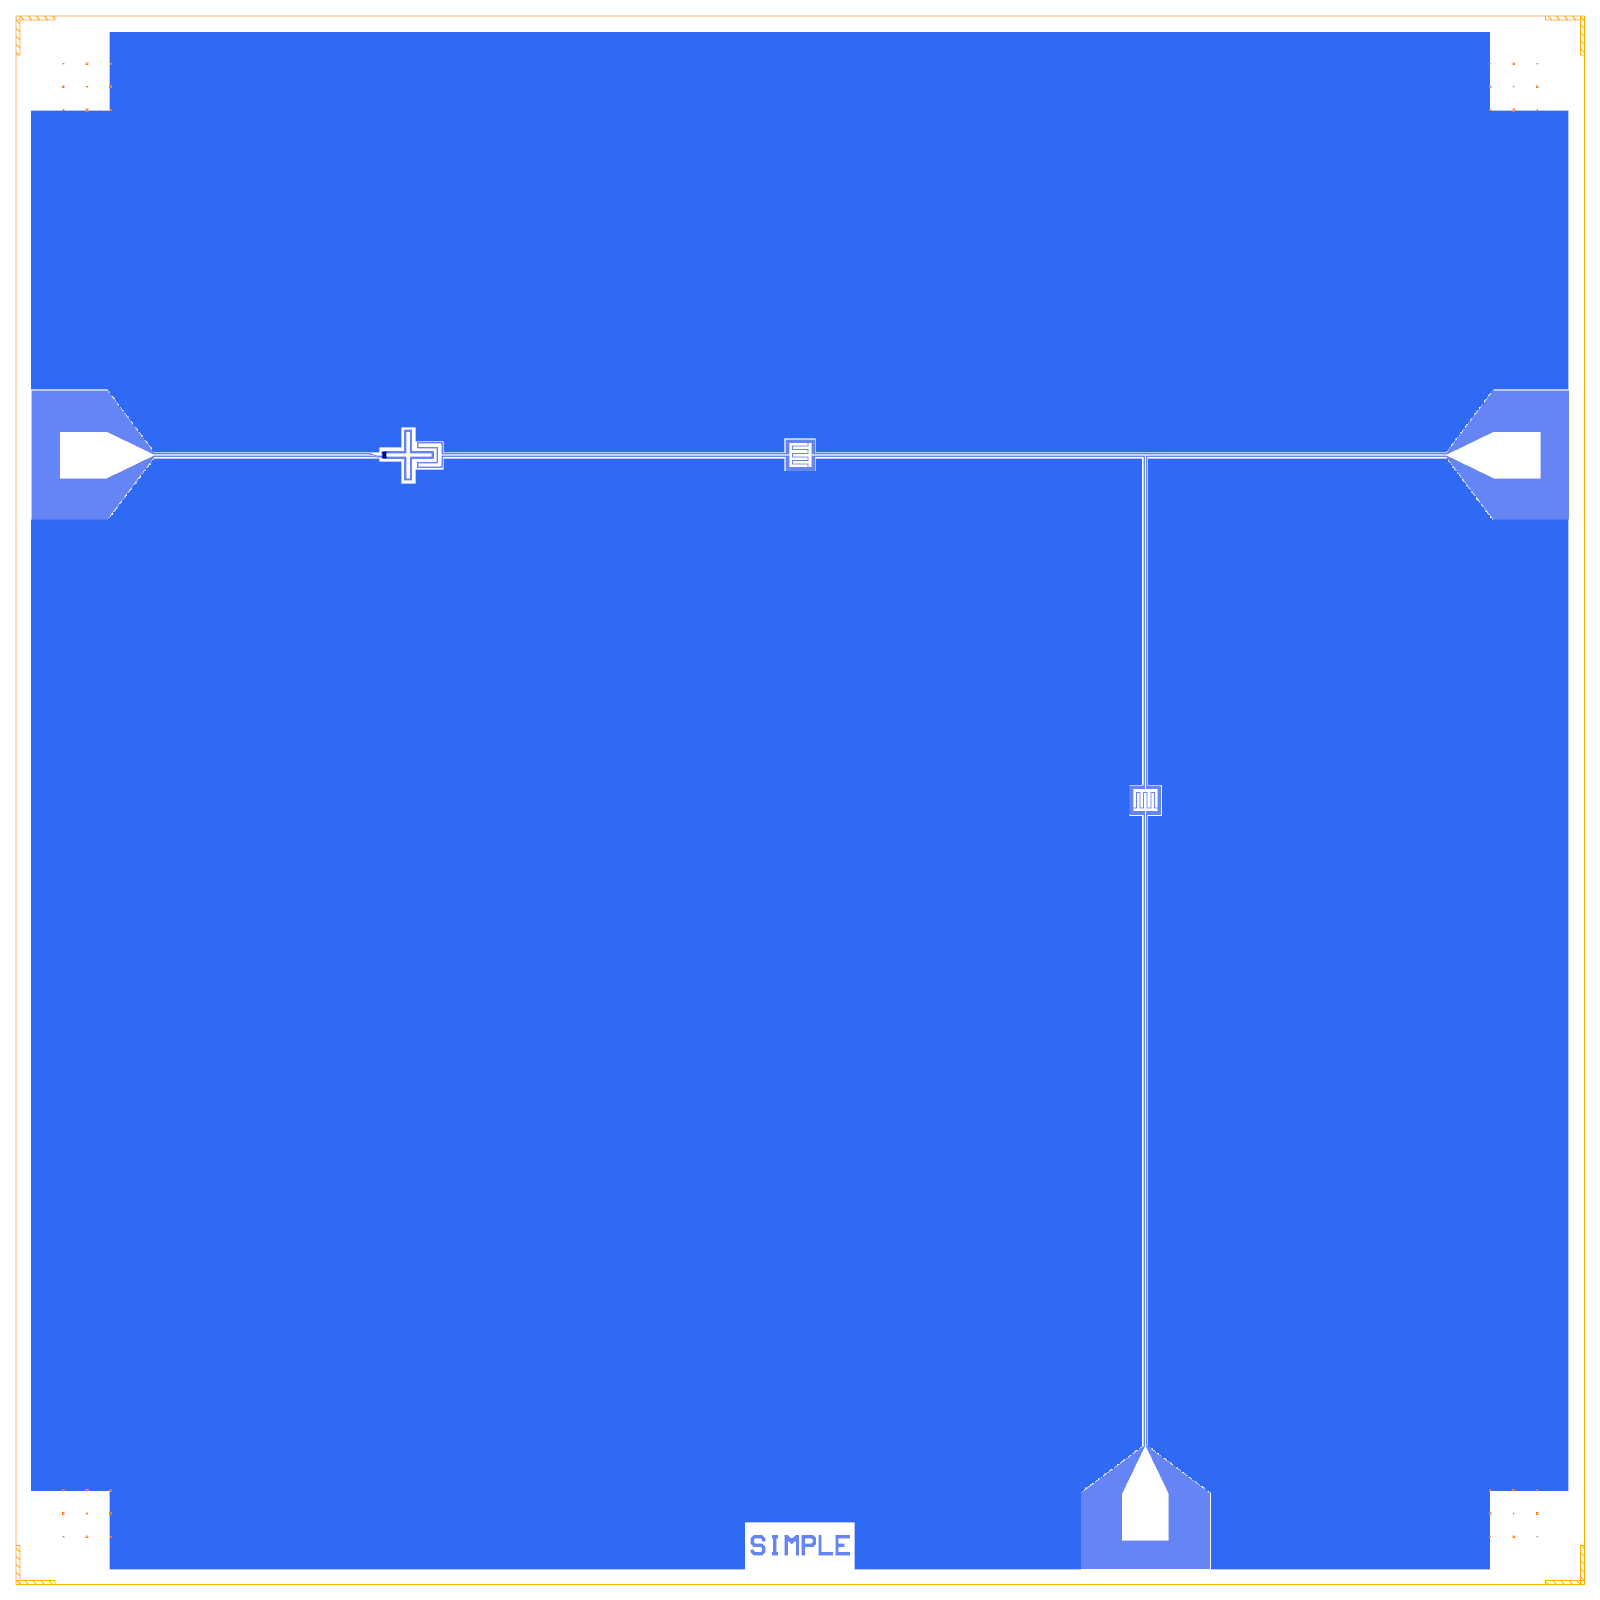

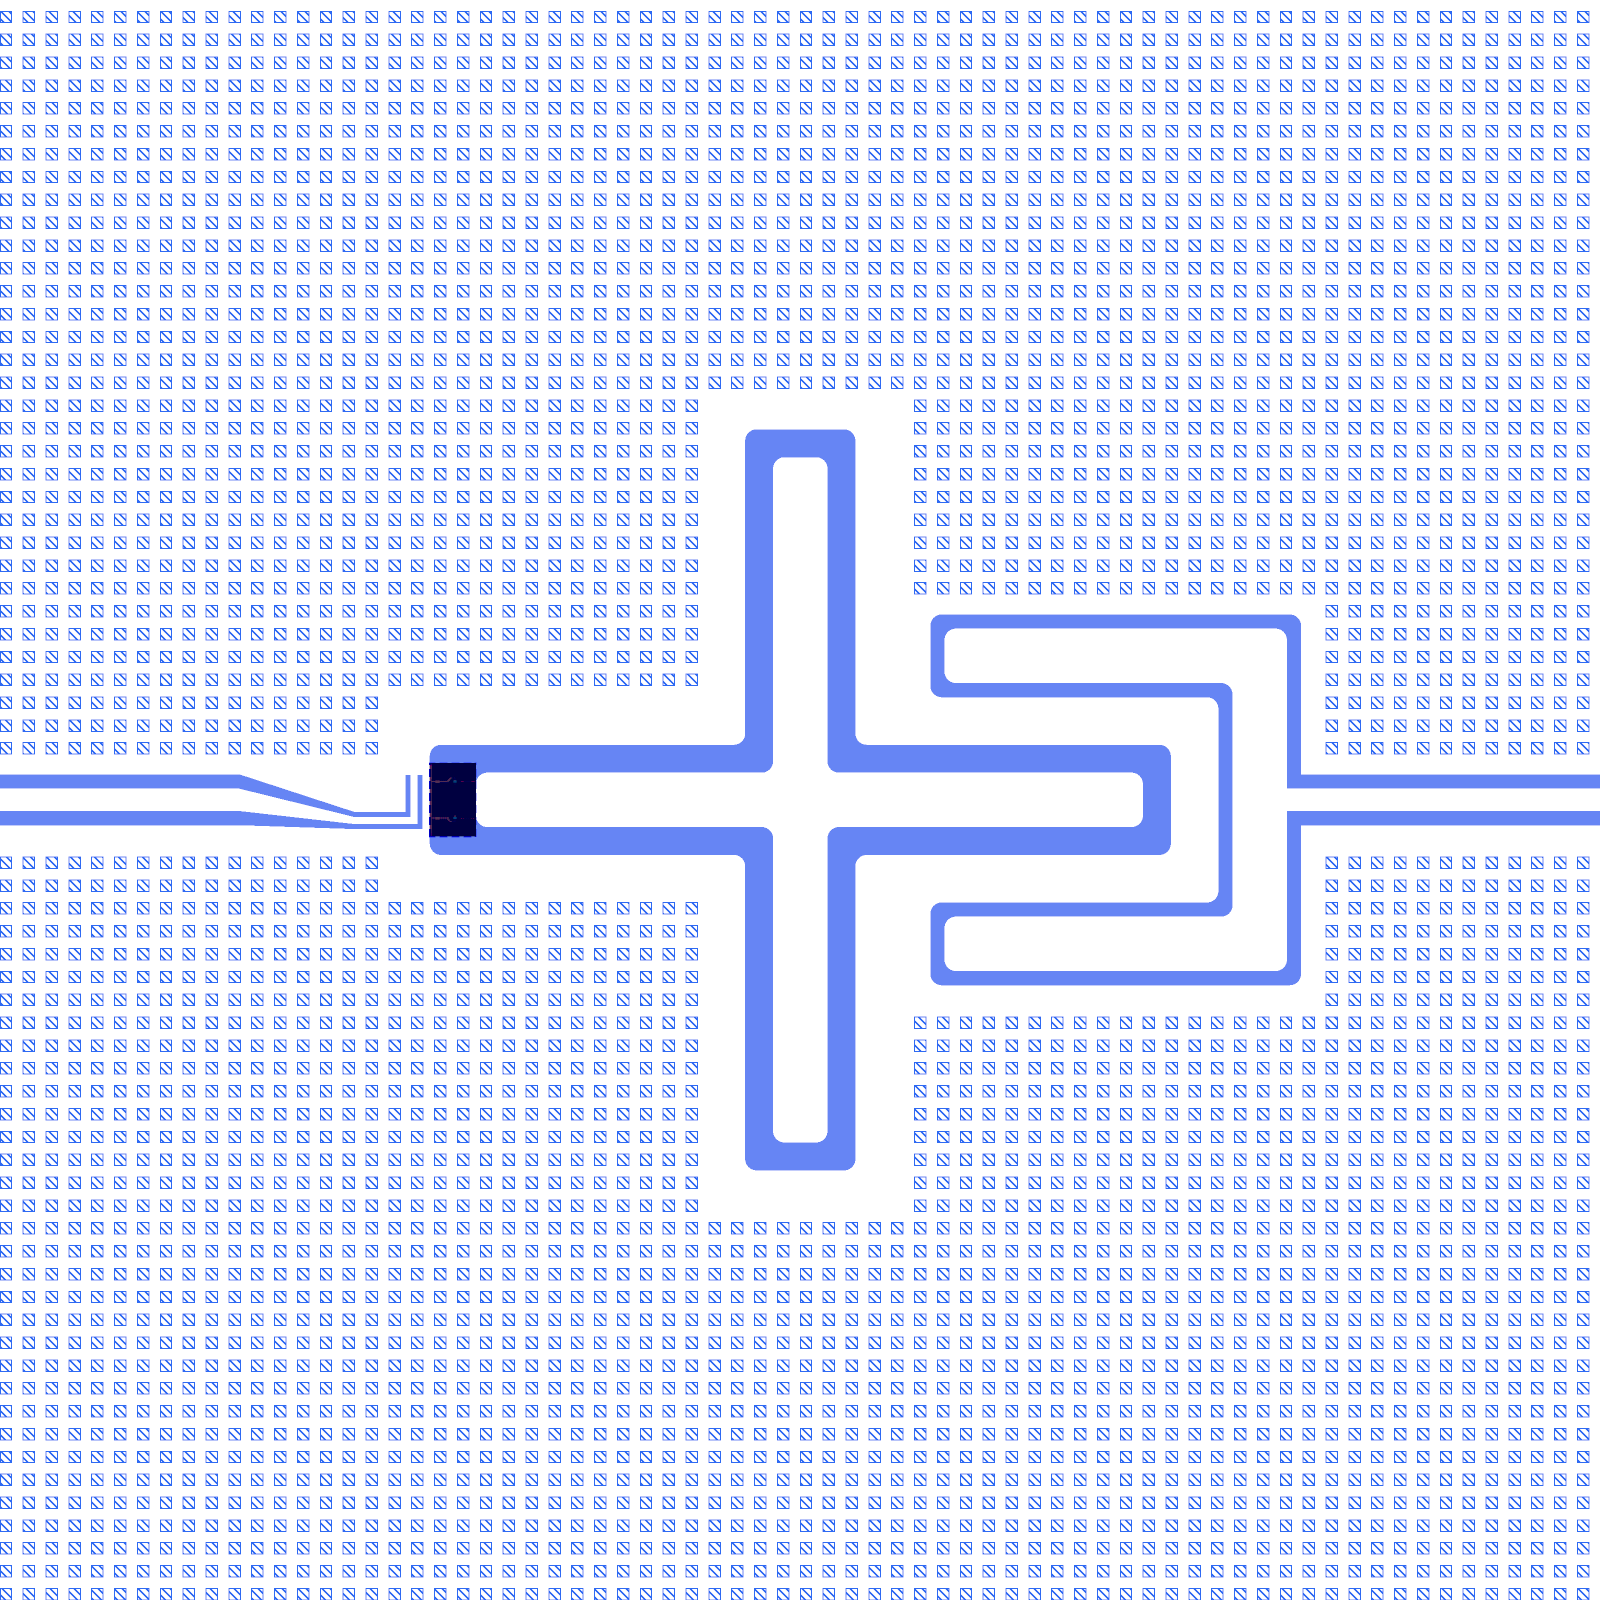

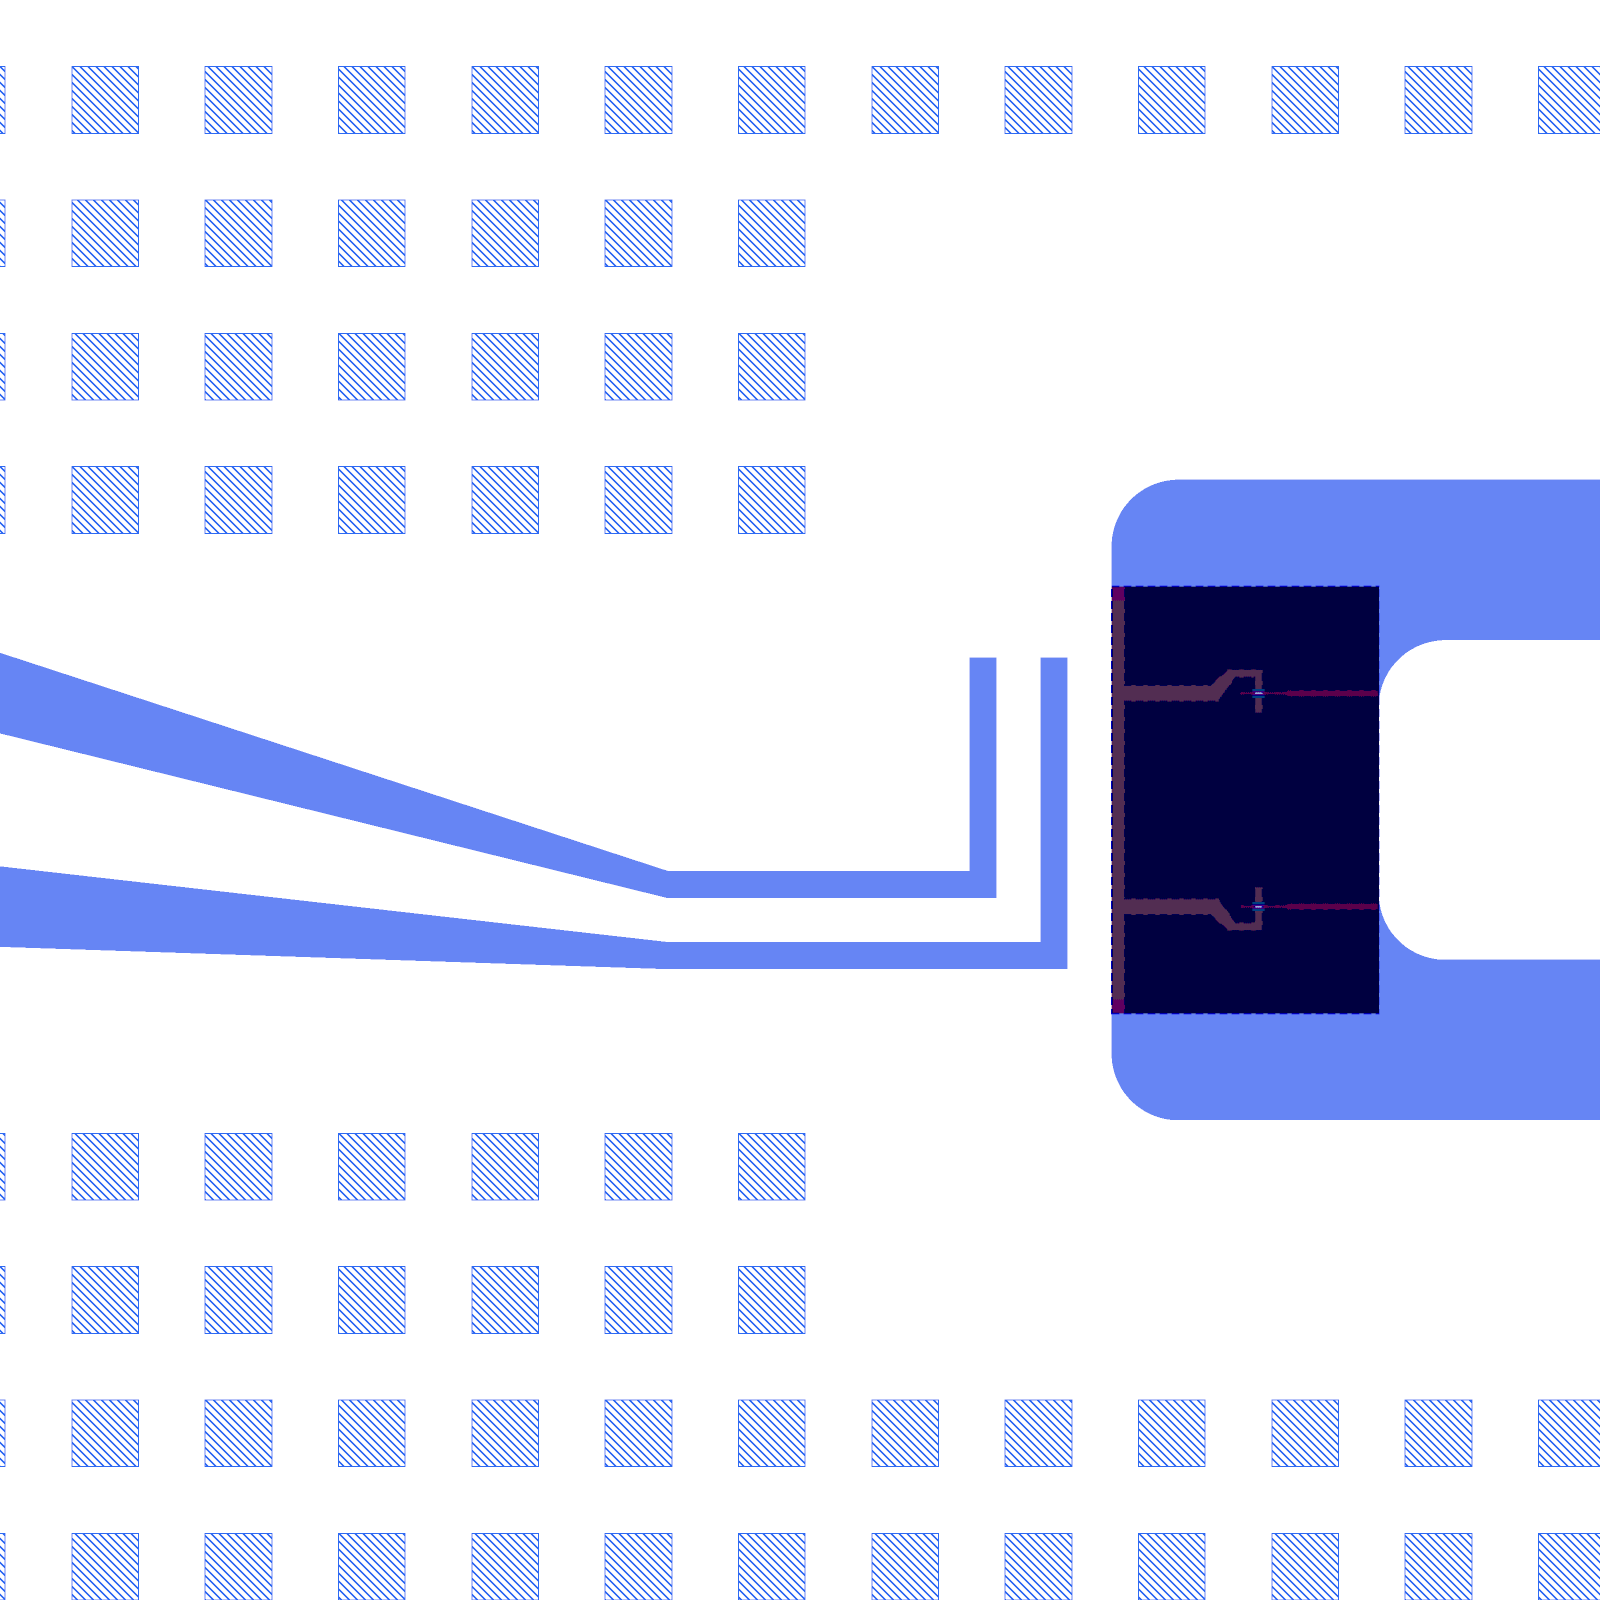

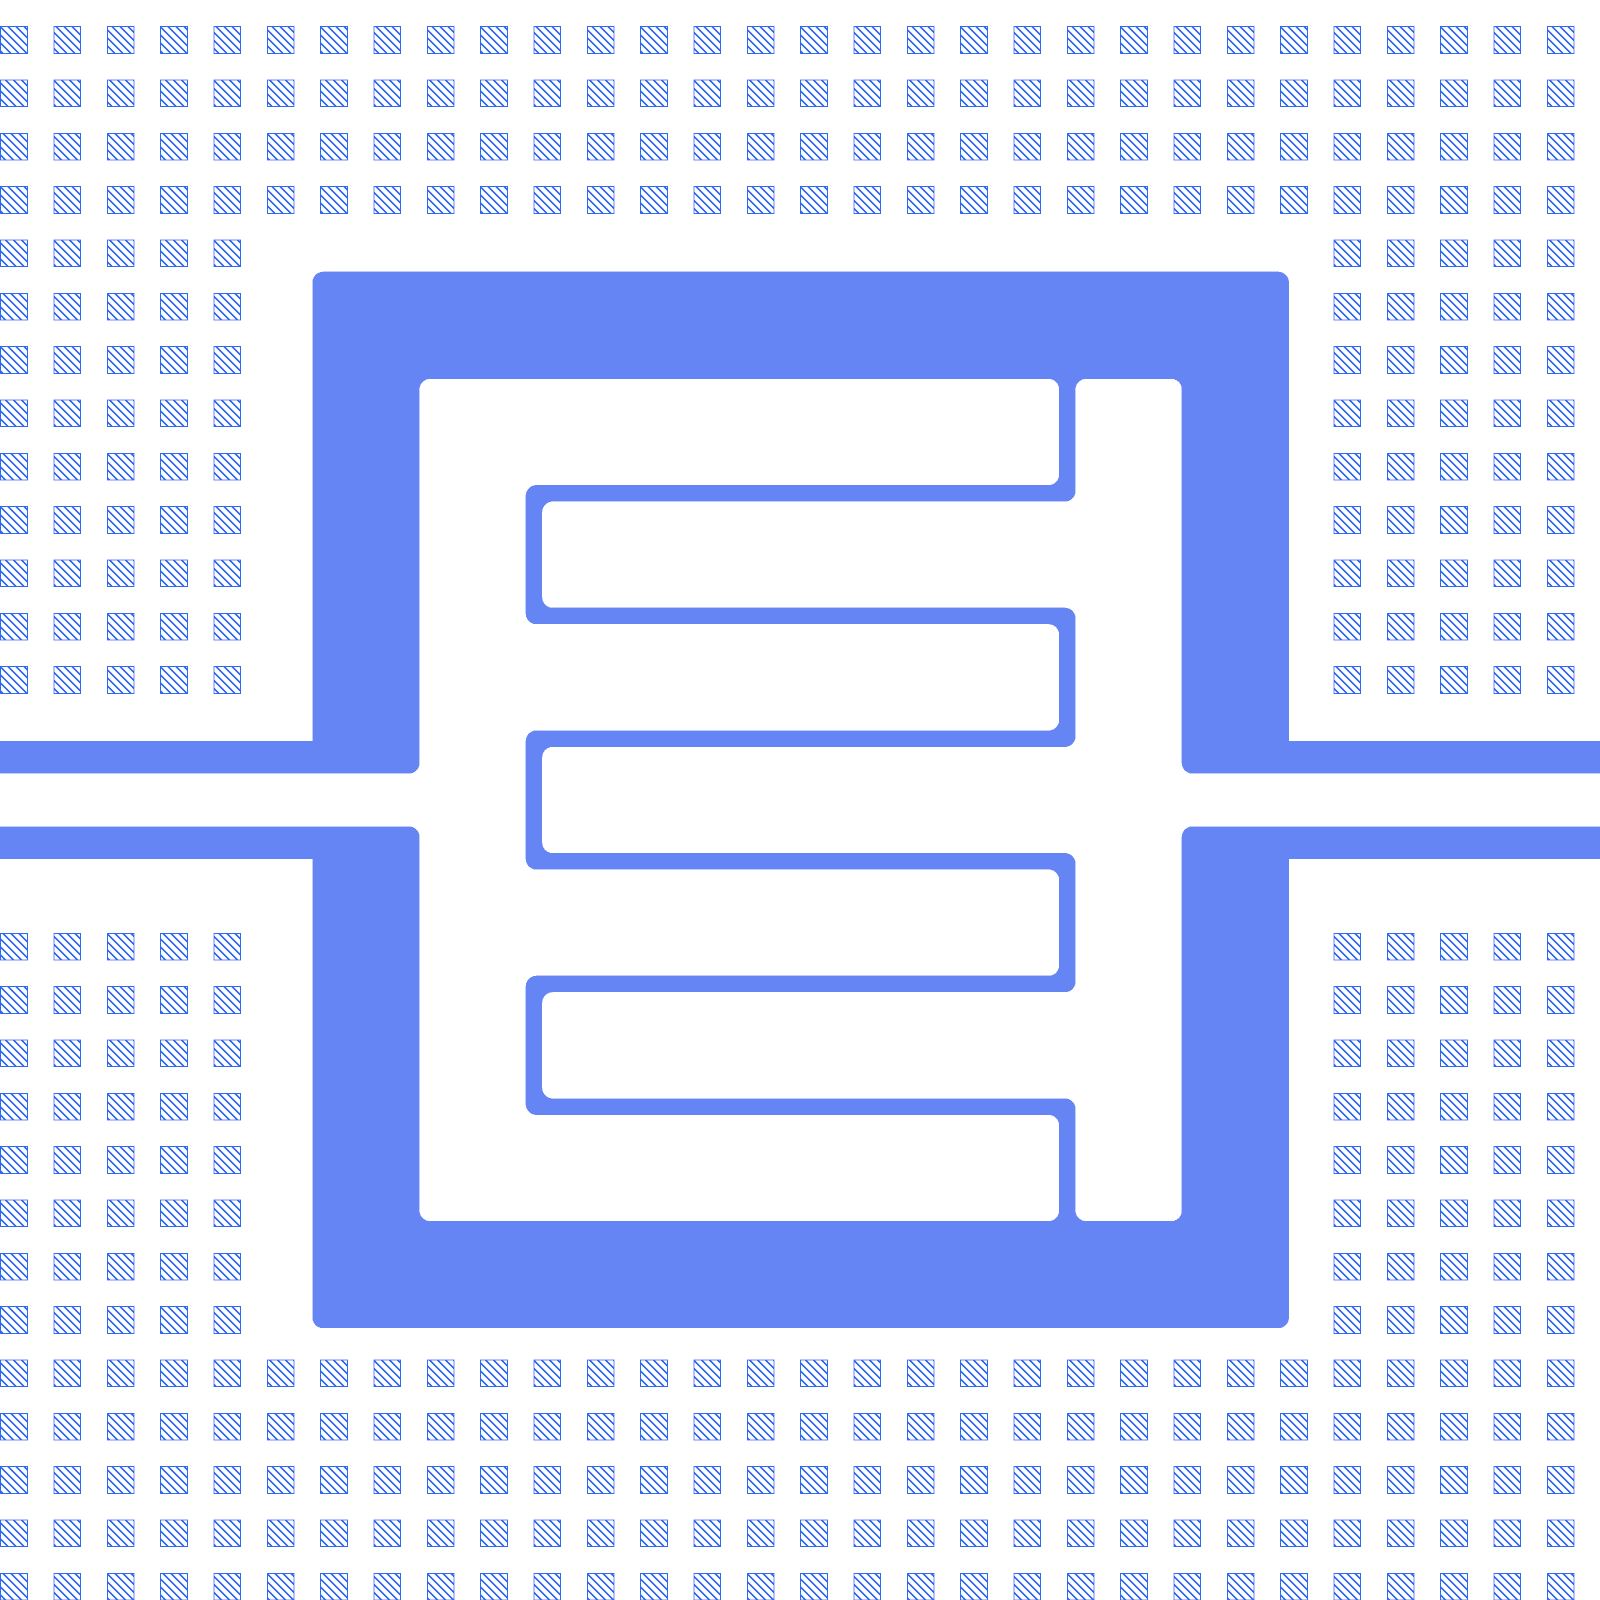

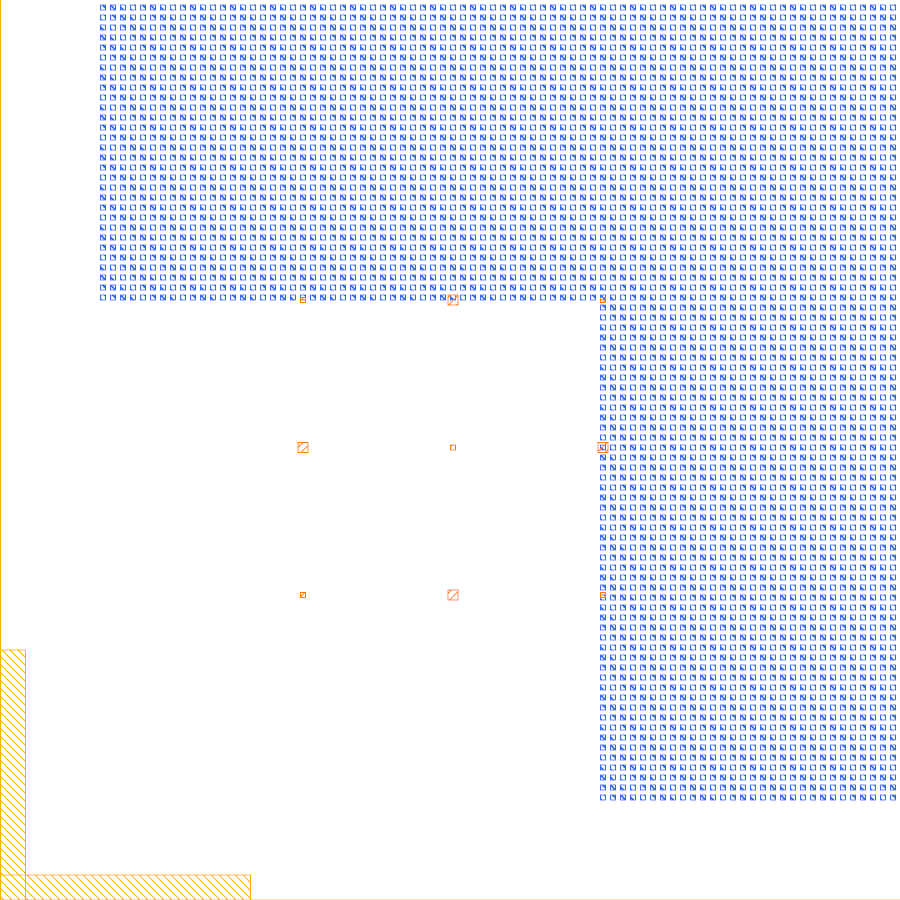

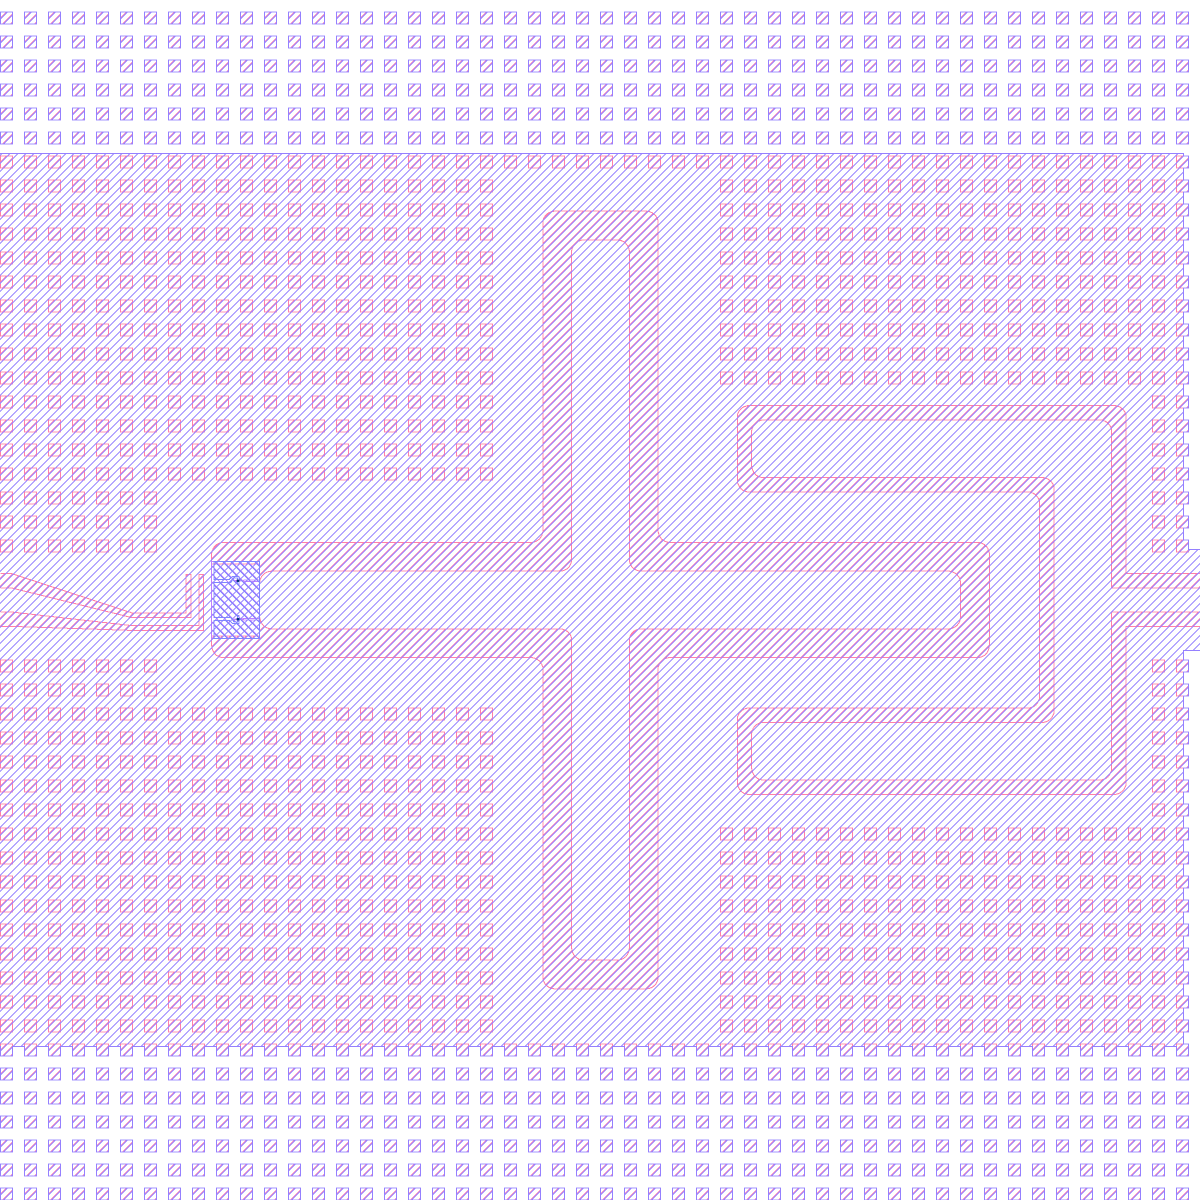

In [17]:
show_snapshot(d, OUT / "simple.png")
show_snapshot(d, OUT / "simple_qb.png", box=(2150, 6850, 2850, 7550), width=420)
fx, fy = port_xy(d, "QB.flux")
show_snapshot(d, OUT / "simple_squid.png", box=(fx, fy - 60, fx + 120, fy + 60), width=360)
show_snapshot(d, OUT / "simple_coupler.png", box=(4850, 7050, 5150, 7350), width=360)
show_snapshot(d, OUT / "simple_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "simple_fab.oas", OUT / "simple_fab_qb.png", box=(2250, 6950, 2750, 7450),
          size=(1200, 1200), width=420);   # fab view: 1/0 with the grid holes, 3/0, junction layers

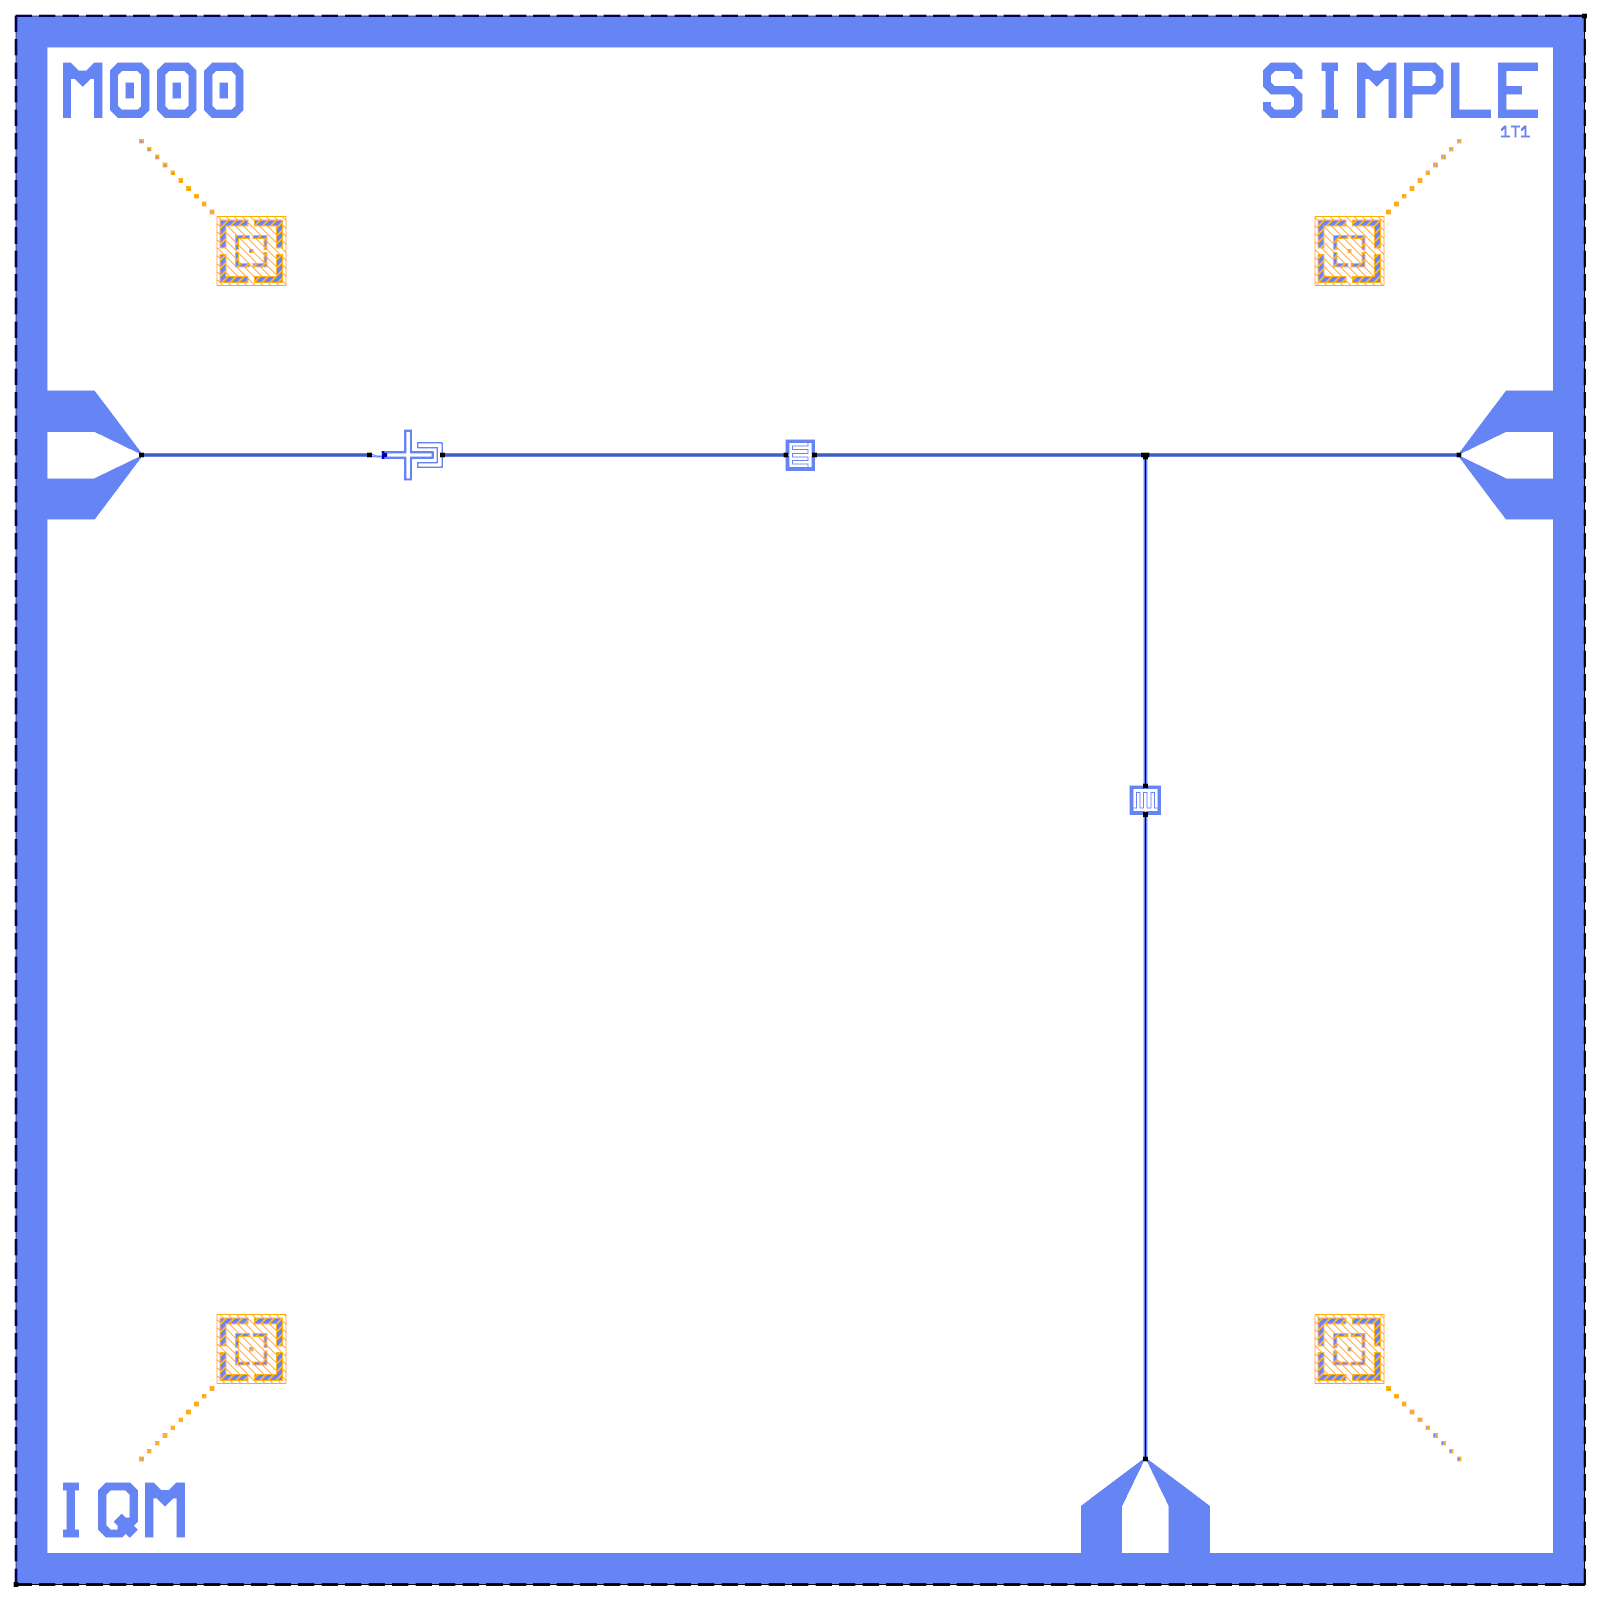

In [18]:
from kqcircuits.chips.simple import Simple
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
top = ref.create_cell("kqc_simple")
top.insert(pya.DCellInstArray(Simple.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "simple_kqc_original.oas"))
snap_file(Path("build") / "simple_kqc_original.oas", OUT / "simple_kqc.png", box=(-100, -100, 10100, 10100),
          width=420);

**Reference: XOR with the source.** KQC's `Simple` built stand-alone, XOR-ed layer by layer with this build
(`refpoints` and the `instance_names` label layer are annotation and are skipped). **The rebuild is expected to
differ** by design — the frame (KQC's ChipFrame vs the Quantcore die frame), the junction layers (KQC Manhattan
SQUID → trilayer SQUID on 2/0 + 4/0 + 50/0), the ground grid (KQC's build here has none) and the 80 µm launcher
shift; the KQC elements and routes should otherwise agree. A reference, not a pass/fail check.

In [19]:
import klayout.db as kdb

ly = kdb.Layout()
ly.read(str(d.out))
top_d = ly.top_cell()
by_name = {ly.get_info(i).name: i for i in ly.layer_indexes()}
rows, total = ["| layer | XOR area (µm²) |", "|---|---|"], 0.0
for li in ref.layer_indexes():
    info = ref.get_info(li)
    a = kdb.Region(top.begin_shapes_rec(li)).merged()
    if a.is_empty() or info.name in ("refpoints", "instance_names"):
        continue
    b = kdb.Region(top_d.begin_shapes_rec(by_name[info.name])).merged() if info.name in by_name else kdb.Region()
    x = (a ^ b).area() * ref.dbu ** 2
    total += x
    rows.append(f"| {info.name} ({info.layer}/{info.datatype}) | {x:.3g} |")
display(Markdown("\n".join(rows) + f"\n\n**Total XOR area: {total:.3g} µm²**"))

| layer | XOR area (µm²) |
|---|---|
| 1t1_base_metal_gap_wo_grid (130/1) | 8.76e+06 |
| 1t1_ground_grid_avoidance (133/1) | 1.39e+07 |
| 1t1_base_metal_addition (131/1) | 686 |
| 1t1_SIS_junction (136/1) | 470 |
| 1t1_SIS_junction_2 (139/1) | 580 |
| 1t1_waveguide_path (135/1) | 2.4e+03 |
| 1t1_base_metal_gap_for_EBL (134/1) | 8.68e+06 |
| 1t1_SIS_shadow (137/1) | 406 |
| 1t1_chip_dicing (158/1) | 2.68e+05 |
| 1t1_airbridge_pads (146/1) | 5.4e+05 |
| 1t1_airbridge_flyover (147/1) | 2.81e+05 |

**Total XOR area: 3.24e+07 µm²**

## 15 · Summary

| | |
|---|---|
| **matches the source** | every KQC element with its parameters, positions and orientations; the three SMA8 launchers; the six straight routes; KQC's whole-area ground grid |
| **differs (PDK)** | Quantcore die frame instead of KQC's ChipFrame; launchers 80 µm further in (outer etch 100 µm from the edge, `frame.pad_edge`); sapphire instead of silicon; Quantcore trilayer SQUID (f_q ≈ 6.0 GHz instead of ≈ 4.7 GHz) |
| **placement** | kept off-centre (≈ −879 µm in y): the fixed launcher ports set the content box, as in the source |
| **PDK design warnings** | none (the SQUID's parallel R_n is 45 kΩ, f_q ≈ 6.0 GHz) |
| **FEM** | 2 jobs exported (`build/jobs/simple_QB_C1_*`: Q3D + eigenmode), not solved here |